In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize
from scipy.optimize import minimize
from scipy.stats import norm
from scipy.special import logsumexp
import warnings
from scipy.optimize import curve_fit
from scipy.optimize import approx_fprime
import scipy.stats as stats
from pybads import BADS

from matplotlib.colors import LinearSegmentedColormap

# TEMP
warnings.simplefilter("ignore", category=FutureWarning)

from src.src import *

# Set some defaults
sns.set_theme(font_scale=1.2)
sns.set_style("ticks")
# sns.set_palette('deep')

plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams["mathtext.default"] = "regular"

%config InlineBackend.figure_format = "retina"

## The Plan

### Parameter and model recovery 
1) Simulate data using best-fit parameters from each model (or samples from within the range of best-fits). For example, 100 simulations of each model within range of best-fit parameters.
2) Refit simulated data using MLE.
3) Correlate parameters used for simulation with recovered parameters.
4) Model comparison with AIC/BIC. 

In [2]:
# Read in behavioral data
sdt = pd.read_csv("../behavioural/data/processed-sdt.csv")
adapt = pd.read_csv("../behavioural/data/processed-adapt.csv")

# Read in csv with MLEs from all models
# Need a function to convert string back to numpy array
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')

fits_sdt = pd.read_csv("model-fits/fits_sdt.csv", converters={"params":converter})
fits_adapt = pd.read_csv("model-fits/fits_adapt.csv", converters={"params":converter})
fits_sdt.head()


,SN,model,fit_task,nll,aic,bic,params,C,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert,aic_weighted,bic_weighted
0,1,vco,sdt,318.538186,643.076371,657.122697,"[3.41250859, 1.82921363, -0.11052107]",3.412509,1.829214,-0.110521,NaN,NaN,NaN,NaN,NaN,935.269293,950.448146
1,2,vco,sdt,286.700472,579.400945,593.447271,"[5.1097239, 2.46265332, 2.78463823]",5.109724,2.462653,2.784638,NaN,NaN,NaN,NaN,NaN,843.107896,858.289325
2,3,vco,sdt,466.611546,939.223091,953.189412,"[3.46698499, 3.8885529, 0.20789672]",3.466985,3.888553,0.207897,NaN,NaN,NaN,NaN,NaN,1309.749891,1324.719279
3,4,vco,sdt,367.046285,740.092570,754.142653,"[4.10714784, 2.64430312, 0.25845051]",4.107148,2.644303,0.258451,NaN,NaN,NaN,NaN,NaN,1071.766434,1086.934960
4,5,vco,sdt,266.566256,539.132513,553.178838,"[4.82265147, 2.26528203, 0.07786751]",4.822651,2.265282,0.077868,NaN,NaN,NaN,NaN,NaN,783.651936,798.830789


---
## Processing for adaptation simulations

---
## Read / Write parameters

In [3]:
# Save MLEs? Set to True ONLY if you want to save a new set of fit parameters.
write_data = False

# Read-in saved parameters? Set to True if you want to check previous fit(s).
read_data = True
read_sdt = True
read_adapt = True

# Helper function
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')
    
# Write data to csv
if write_data:
    if sdt_recovery is not None:
        sdt_recovery.to_csv("model-fits/sdt_model_recovery.csv", index=False)
    if adapt_recovery is not None:
        adapt_recovery.to_csv("model-fits/adapt_model_recovery.csv", index=False)

# Read in csv from previous param/model recovery analysis; need "converter" helper fxn
# because parameters must be converted from string representation of values to 1-d NumPy 
# array
if read_data:
    if read_sdt:
        sdt_recovery = pd.read_csv("model-fits/sdt_model_recovery.csv", 
                               converters={"simulated_params":converter, 
                                        "recovered_params":converter})
    if read_adapt: 
        adapt_recovery = pd.read_csv("model-fits/adapt_model_recovery.csv", 
                               converters={"simulated_params":converter, 
                                          "recovered_params":converter})


In [4]:
# Group by model and stack params into 2d array
params = fits_adapt.groupby("model")["params"].apply(np.stack)
params_vco = params["vco"]
params_co = params["co"]
params_piece = params["piece"]

# Set upper and lower bounds on simulated params
vco_lb = params_vco.min(axis=0)
vco_ub = params_vco.max(axis=0)
co_lb = params_co.min(axis=0)
co_ub = params_co.max(axis=0)
piece_lb = params_piece.min(axis=0)
piece_ub = params_piece.max(axis=0)


# Choose subject to extract experiment parameters from (same for all 16 subjects)
subj_id = 1
adapt = adapt.loc[adapt["TN"] > 100, :].reset_index(drop=True)
adapt_subj = adapt.loc[(adapt["SN"] == subj_id) & (adapt["session"] == "adapt"), :].reset_index(drop=True)
cols_to_copy = ["SN", "TN", "session", "delta_xv", "vis_fb", "x_f", "sigma_motor_adapt"]
simsubj = pd.DataFrame()
simsubj[cols_to_copy] = adapt_subj[cols_to_copy]
simsubj["no_fit"] = False

In [ ]:
%%time
# How many model simulations?
n_modelsims = 34

# Determine how many MC simulations to run
n_mcsims = 1000
n_inits = 1

# We switch off the printing from BADS
options = {"display" : 'off'}

fit_task = "adapt"

n_decimals = 5

models = ["vco", "co", "piece"]
# models = ["vco", "co"]
simulated_params = []
recovered_params = []
model = []
winner_bic = []
winner_aic = []
iteration = []

resp_vco = np.zeros((n_modelsims, len(adapt_subj)))
resp_co = np.zeros((n_modelsims, len(adapt_subj)))
resp_piece = np.zeros((n_modelsims, len(adapt_subj)))

adapt_recovery = pd.DataFrame()

# This next loop is for both model and parameter recovery
for i in range(n_modelsims):
    print(f"i:{i}")
    # Generate parameter vals for each model
    vco_simparams = np.random.uniform(low=vco_lb, high=vco_ub)
    co_simparams = np.random.uniform(low=co_lb, high=co_ub)
    piece_simparams = np.random.uniform(low=piece_lb, high=piece_ub)

    # Loop through models
    for j in range(len(models)):
        print(f"j:{    j}")
        if j == 0:
            # VCO model
            resp_vco[i, :] = vco_simulate_adapt(
                df=simsubj,
                C=vco_simparams[0], 
                B=vco_simparams[1], 
                sigma_v=vco_simparams[2], 
                b=vco_simparams[3], 
            )
            simulated_model = "vco"
            simulated_params.append(vco_simparams)
            simsubj["x_f"] = resp_vco[i, :]  
        elif j == 1: 
            # CO model
            resp_co[i, :] = co_simulate_adapt(
                df=simsubj,
                C=co_simparams[0],
                B=co_simparams[1],
                sigma_comb=co_simparams[2],
                b=co_simparams[3],
            )
            simulated_model = "co"
            simulated_params.append(co_simparams)
            simsubj["x_f"] = resp_co[i, :]
        elif j == 2:
            # PIECE model
            resp_piece[i, :] = piece_simulate_adapt(
                df=simsubj,
                alpha=piece_simparams[0], 
                beta=piece_simparams[1],
                sigma_p=piece_simparams[2],
                sigma_pert=piece_simparams[3],
                b=piece_simparams[4],
            )
            simulated_model = "piece"
            simulated_params.append(piece_simparams)
            simsubj["x_f"] = resp_piece[i, :]
            
        # Fit simulated data:
        # VCO: Parameter bounds (C, B, sigma_v, b) 
        bounds       = [(0.1, 10), (0.01, 1), (0.1, 10.0), (-5, 5)]
        plaus_bounds = [(0.5, 5), (0.05, 0.6), (0.5, 6), (-2.5, 2.5)]
        fits_vco, aic_vco, bic_vco = fit_bads("vco", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                              n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "vco":
            recovered_params.append(np.round(fits_vco.x, n_decimals))

        # CO parameter bounds (C, B, sigma_comb, b) 
        bounds       = [(0.1, 10), (0.01, 1), (0.1, 10.0), (-5, 5)]
        plaus_bounds = [(0.5, 5), (0.05, 0.6), (0.5, 6), (-2.5, 2.5)]
        fits_co, aic_co, bic_co = fit_bads("co", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                     n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "co":
            recovered_params.append(np.round(fits_co.x, n_decimals))

        # PIECE parameter bounds: alpha, beta, sigma_p, sigma_pert, b,
        bounds       = ((0.1, 5), (0.001, 1), (0.1, 10), (0.1, 120), (-5, 5))
        plaus_bounds = ((0.5, 4), (0.01, 0.5), (0.3, 6), (3, 20), (-2.5, 2.5))
        fits_piece, aic_piece, bic_piece = fit_bads("piece", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                        n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "piece":
            recovered_params.append(np.round(fits_piece.x, n_decimals))

        # These lines are for model comparison/recovery: store winning model
        winner_aic.append(models[np.argmin([aic_vco, aic_co, aic_piece])])
        winner_bic.append(models[np.argmin([bic_vco, bic_co, bic_piece])])
        # winner_aic.append(models[np.argmin([aic_vco, aic_co, ])])
        # winner_bic.append(models[np.argmin([bic_vco, bic_co, ])])
        
        # Update variables to properly index in dataframe
        model.append(simulated_model)
        iteration.append(i)

# Store variables in data frame
adapt_recovery = pd.DataFrame({
    "iteration": iteration,
    "model":model, 
    "winner_aic":winner_aic, 
    "winner_bic":winner_bic,
    "simulated_params": simulated_params,
    "recovered_params": recovered_params, 
})
        

---
## Model recovery analysis for adaptation task

Build confusion matrix. 

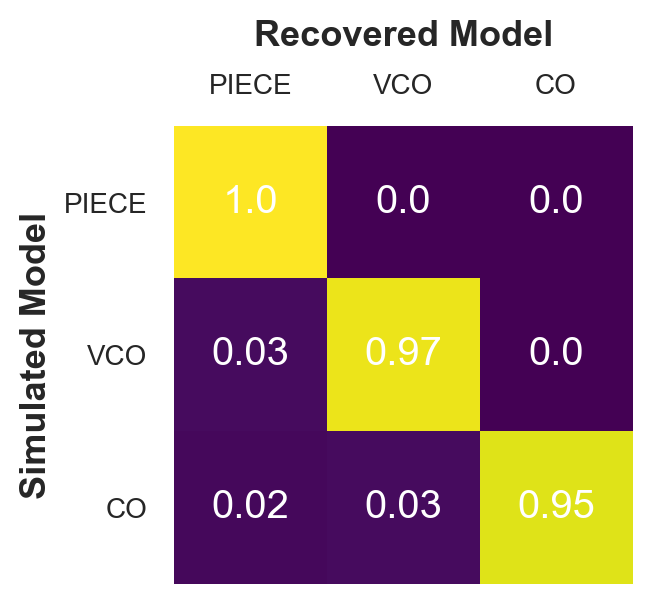

In [29]:
save = 0
df_recovery = adapt_recovery
models = ["piece", "vco", "co"]
y_true = adapt_recovery["model"]
y_pred = adapt_recovery["winner_aic"]
df_confusion = pd.crosstab(adapt_recovery["model"], adapt_recovery["winner_aic"], normalize="index")
df_confusion

def plot_confusion_matrix(df_confusion, title=None, save=0):
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    ax.matshow(df_confusion, cmap="viridis") 
    plt.title(title, fontsize=13)
    tick_marks = np.arange(len(df_confusion.columns))
    ax.set_xticks(tick_marks, ["PIECE", "VCO", "CO"])
    ax.xaxis.tick_top()
    ax.set_yticks(tick_marks, ["PIECE", "VCO", "CO"])
    ax.set_ylabel("Simulated Model", weight="bold", fontsize=13)
    ax.set_xlabel("Recovered Model", weight="bold", fontsize=13, labelpad=10)
    ax.xaxis.set_label_position('top')
    ax.tick_params(left=False, top=False)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    # plt.text(-2, -1.2, "b", weight="bold", fontsize=14)

    # Loop over data dimensions and create text annotations.
    for i in range(len(models)):
        for j in range(len(models)):
            ax.text(j, i, df_confusion.iloc[i, j],
                           ha="center", va="center", color="w")
    plt.tight_layout()
    if save:
        plt.savefig("../figs/model_recovery_adapt.pdf", dpi=300)

# Doing this because colors were washed out in illustrator
import matplotlib as mpl
mpl.rcParams['pdf.compression'] = 0
plot_confusion_matrix(df_confusion, save=1)

---
## Parameter recovery analysis for adaptation task

In [23]:
# Unpack parameters and stack them into 2d arrays
df_simparams = adapt_recovery.groupby("model")["simulated_params"].apply(np.stack)
df_fitparams = adapt_recovery.groupby("model")["recovered_params"].apply(np.stack)

# Select PIECE parameter matrices
piece_simparams = df_simparams["piece"]
piece_fitparams = df_fitparams["piece"]

# Select VCO parameter matrices
vco_simparams = df_simparams["vco"]
vco_fitparams = df_fitparams["vco"]

# Select CO parameter matrices
co_simparams = df_simparams["co"]
co_fitparams = df_fitparams["co"]


In [28]:
# Compute correlation coefficients between true and recovered params
# PIECE
r_piece_alpha, p_piece_alpha = stats.pearsonr(
    x=piece_simparams[:, 0], y=piece_fitparams[:, 0])
r_piece_beta, p_piece_beta = stats.pearsonr(
    x=piece_simparams[:, 1], y=piece_fitparams[:, 1])
r_piece_sigma_p, p_piece_sigma_p = stats.pearsonr(
    x=piece_simparams[:, 2], y=piece_fitparams[:, 2])
r_piece_sigma_pert, p_piece_sigma_pert = stats.pearsonr(
    x=piece_simparams[:, 3], y=piece_fitparams[:, 3])
r_piece_b, p_piece_b = stats.pearsonr(
    x=piece_simparams[:, 4], y=piece_fitparams[:, 4])
print(np.array([r_piece_alpha, r_piece_beta, r_piece_sigma_p, r_piece_sigma_pert, r_piece_b]).round(4))
print(np.array([p_piece_alpha, p_piece_beta, p_piece_sigma_p, p_piece_sigma_pert, p_piece_b]).round(4))


# VCO
r_vco_C, p_vco_C = stats.pearsonr(x=vco_simparams[:, 0], y=vco_fitparams[:, 0])
r_vco_B, p_vco_B = stats.pearsonr(x=vco_simparams[:, 1], y=vco_fitparams[:, 1])
r_vco_sigma_v, p_vco_sigma_v = stats.pearsonr(x=vco_simparams[:, 2], y=vco_fitparams[:, 2])
r_vco_b, p_vco_b = stats.pearsonr(x=vco_simparams[:, 3], y=vco_fitparams[:, 3])
print(np.array([r_vco_C, r_vco_B, r_vco_sigma_v, r_vco_b]).round(4))
print(np.array([p_vco_C, p_vco_B, p_vco_sigma_v, p_vco_b]).round(4))


# CO
r_co_C, p_co_C = stats.pearsonr(x=co_simparams[:, 0], y=co_fitparams[:, 0])
r_co_B, p_co_B = stats.pearsonr(x=co_simparams[:, 1], y=co_fitparams[:, 1])
r_co_sigma_comb, p_co_sigma_comb = stats.pearsonr(x=co_simparams[:, 2], y=co_fitparams[:, 2])
r_co_b, p_co_b = stats.pearsonr(x=co_simparams[:, 3], y=co_fitparams[:, 3])
print(np.array([r_co_C, r_co_B, r_co_sigma_comb, r_co_b]).round(7))
print(np.array([p_co_C, p_co_B, p_co_sigma_comb, p_co_b]).round(7))

[0.5279 0.6005 0.1101 0.5884 0.9981]
[0.     0.     0.2754 0.     0.    ]
[0.7144 0.8697 0.9492 0.998 ]
[0. 0. 0. 0.]
[0.2484885 0.9531238 0.9639839 0.9972774]
[0.0126713 0.        0.        0.       ]


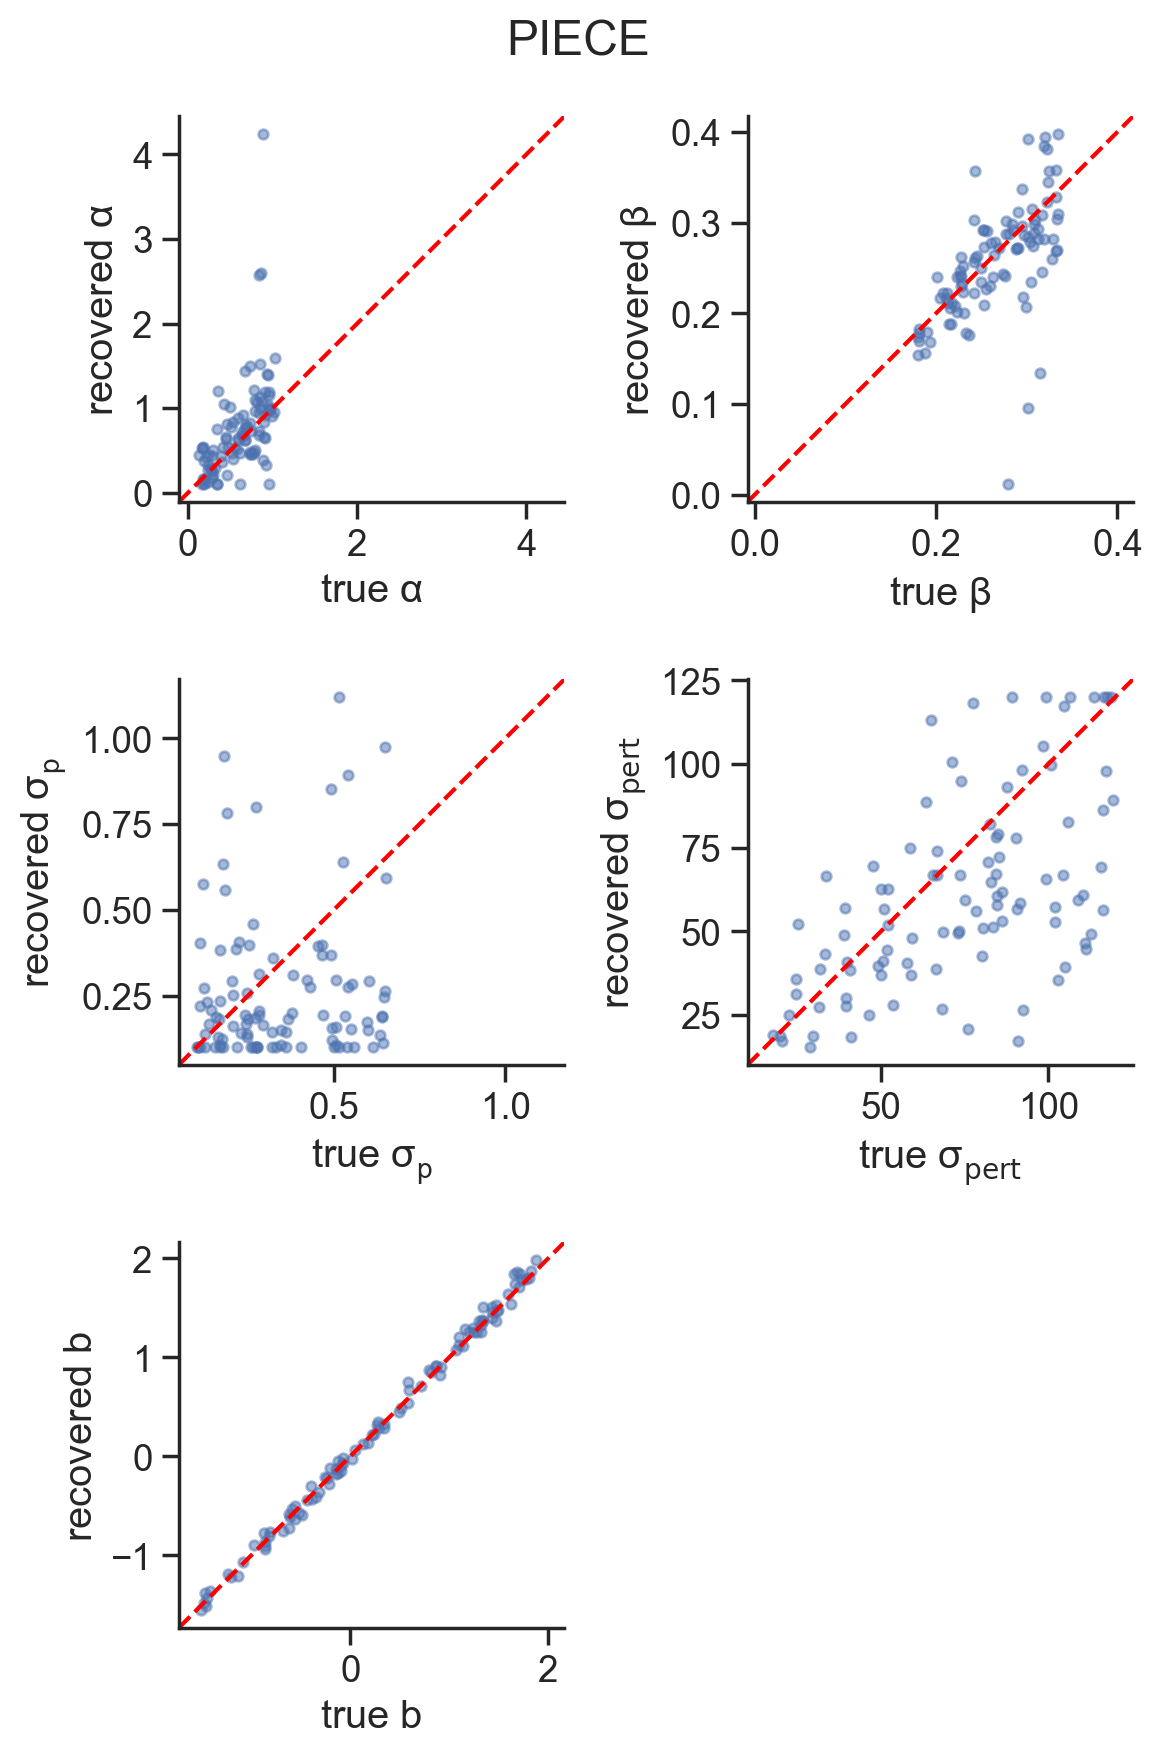

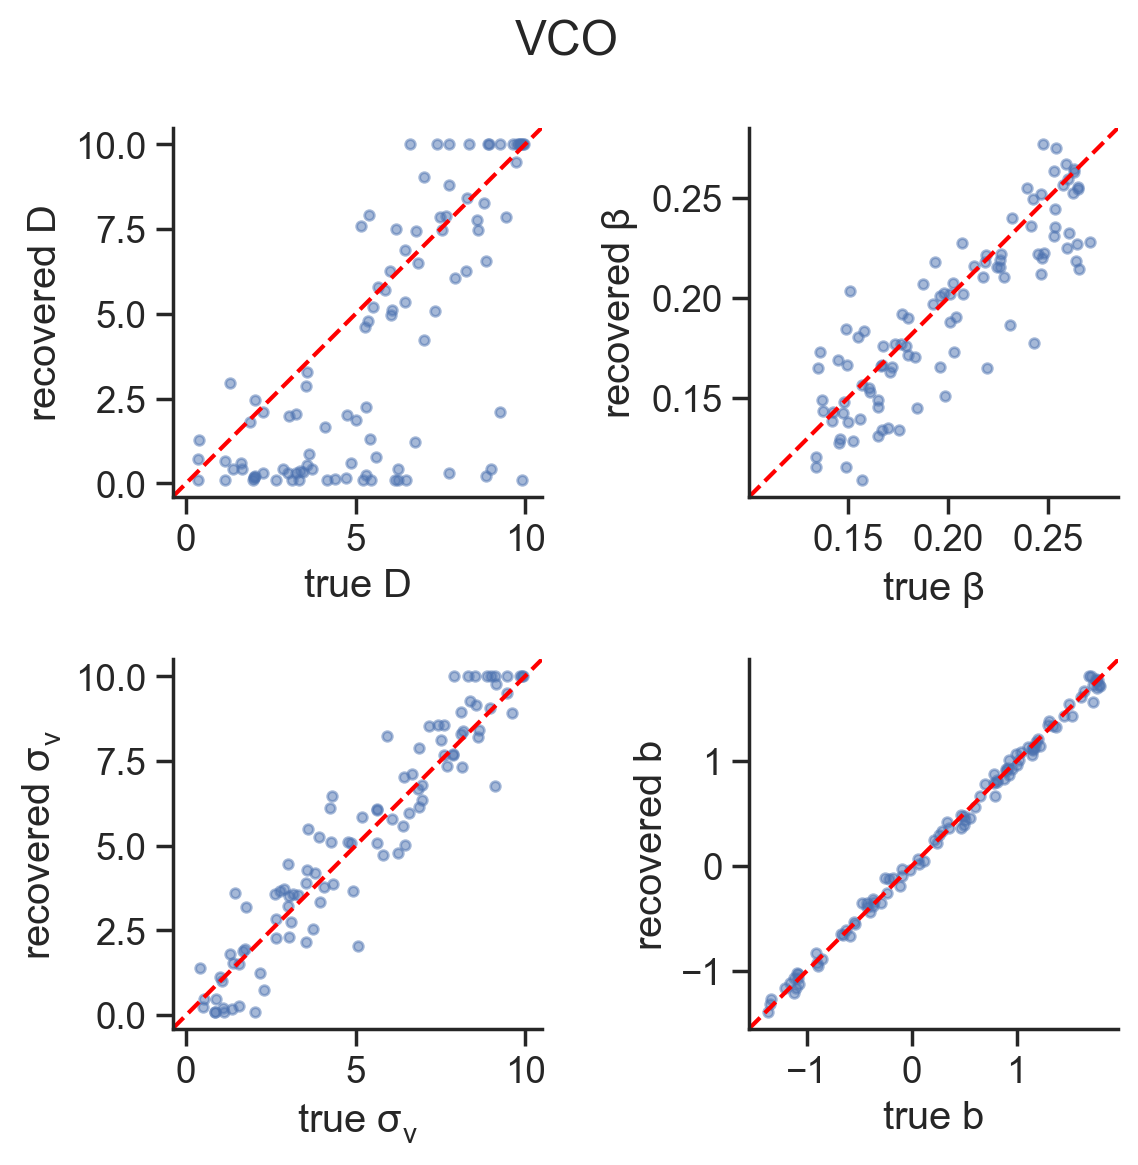

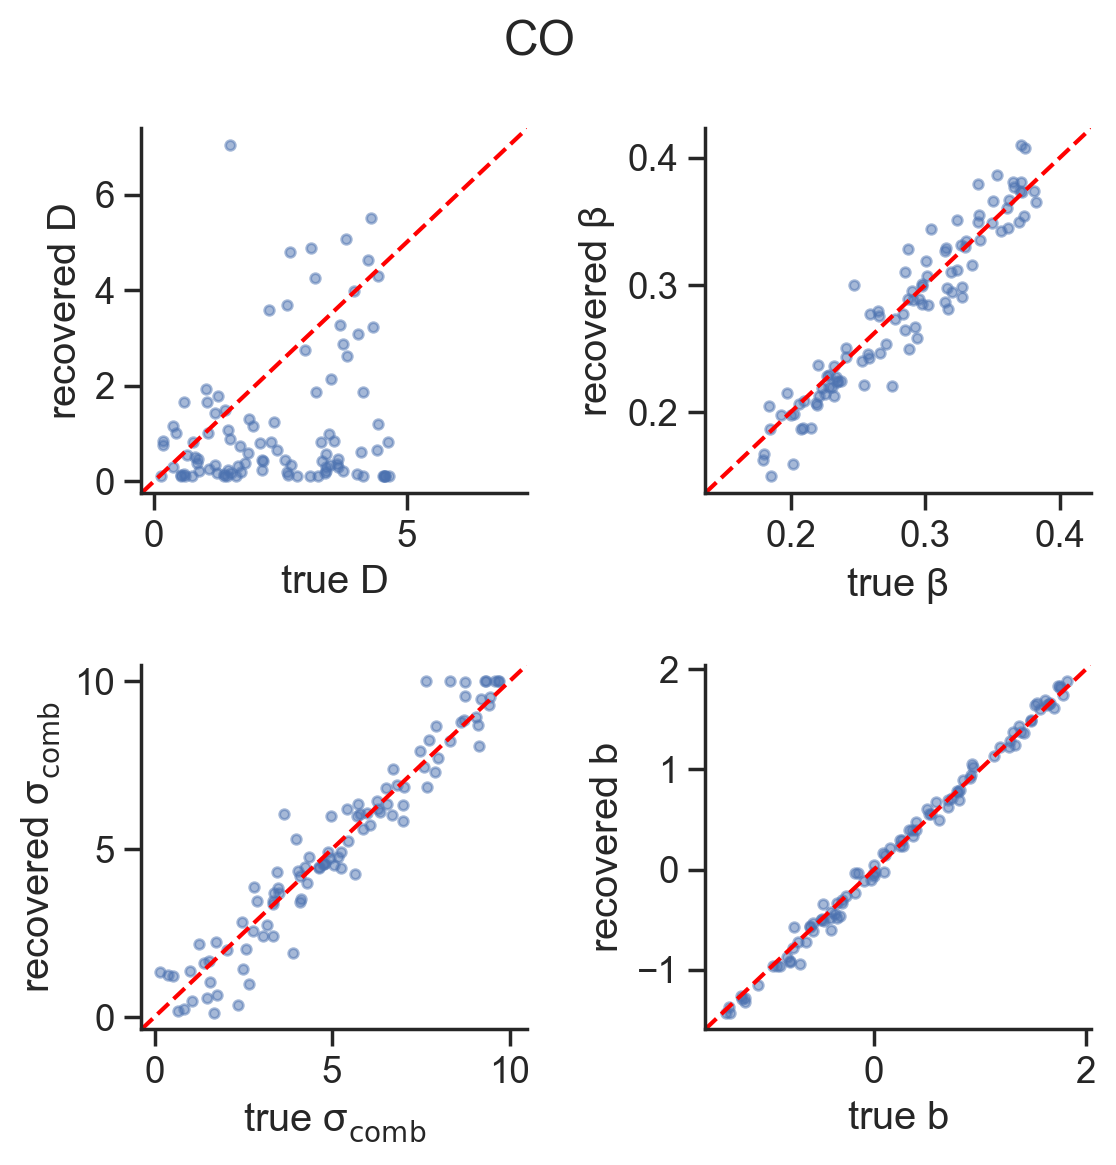

In [26]:
# Plot param recovery for PIECE
fig, axs = plt.subplots(3, 2, figsize=(6, 9))
xaxes = [r"true $\alpha$", r"true $\beta$", r"true $\sigma_p$", r"true $\sigma_\text{pert}$", 
         r"true $b$"] 
yaxes = [r"recovered $\alpha$", r"recovered $\beta$", r"recovered $\sigma_p$", 
         r"recovered $\sigma_\text{pert}$", r"recovered $b$"] 
for i, ax in enumerate(axs.flatten()[:-1]):
    ax.scatter(piece_simparams[:, i], piece_fitparams[:, i], alpha=0.5, s=12)
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    # Get automated data limits
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # Find a shared range so X and Y cover the exact same span
    low = min(xlim[0], ylim[0])
    high = max(xlim[1], ylim[1])
    
    # Force both axes to share this exact same viewport range
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    
    # Plot a standard segment line from corner to corner (low,low to high,high)
    ax.plot([low, high], [low, high], color='red', linestyle='--')
    
    # Force container to be a square frame
    ax.set_aspect('equal', adjustable='box')

fig.suptitle("PIECE")   
axs.flatten()[-1].set_axis_off()
plt.tight_layout()

# Plot param recovery for VCO
fig, axs = plt.subplots(2, 2, figsize=(6, 6))
xaxes = [r"true $D$", r"true $\beta$", r"true $\sigma_v$", r"true $b$"] 
yaxes = [r"recovered $D$", r"recovered $\beta$", r"recovered $\sigma_v$", r"recovered $b$"] 
for i, ax in enumerate(axs.flatten()):
    ax.scatter(vco_simparams[:, i], vco_fitparams[:, i], alpha=0.5, s=12)
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    # Get automated data limits
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # Find a shared range so X and Y cover the exact same span
    low = min(xlim[0], ylim[0])
    high = max(xlim[1], ylim[1])
    
    # Force both axes to share this exact same viewport range
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    
    # Plot a standard segment line from corner to corner (low,low to high,high)
    ax.plot([low, high], [low, high], color='red', linestyle='--')
    
    # Force container to be a square frame
    ax.set_aspect('equal', adjustable='box')

fig.suptitle("VCO")
plt.tight_layout()
    

# Plot param recovery for CO
fig, axs = plt.subplots(2, 2, figsize=(6, 6))
xaxes = [r"true $D$", r"true $\beta$", r"true $\sigma_\text{comb}$", r"true $b$"] 
yaxes = [r"recovered $D$", r"recovered $\beta$", r"recovered $\sigma_\text{comb}$", r"recovered $b$"] 
for i, ax in enumerate(axs.flatten()):
    ax.scatter(co_simparams[:, i], co_fitparams[:, i], alpha=0.5, s=12)
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])

    # Get automated data limits
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # Find a shared range so X and Y cover the exact same span
    low = min(xlim[0], ylim[0])
    high = max(xlim[1], ylim[1])
    
    # Force both axes to share this exact same viewport range
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    
    # Plot a standard segment line from corner to corner (low,low to high,high)
    ax.plot([low, high], [low, high], color='red', linestyle='--')
    
fig.suptitle("CO")
plt.tight_layout()
fig.savefig("../figs/param_recover_co.pdf", dpi=300)